# Player Game Projections

Points, rebounds, assists, steals, blocks and 3-pointers made for each player in each game, using only information available before tip-off. A stat's projected mean is projected minutes times a projected per-minute rate; a negative binomial around that mean gives the probability of reaching any line.

| Model | Inputs |
|---|---|
| Minutes | Pre-season projected minutes per game ([07_season_projections](07_season_projections.ipynb)), expected minutes (projection blended with minutes so far, as in [09_game_outcomes](09_game_outcomes.ipynb)), minutes per game season to date and over the last 5 games, share of games started, expected minutes of absent and available teammates, rank in expected minutes among available players, Elo edge (blowout risk), home, rest, back-to-back |
| Per-minute rate (one per stat) | Rate season to date, over the last 5 games, from the pre-season per-100 projection (3-pointers: projected 3PA at a 36% league-average 3P%), and blended (season to date plus 100-500 minutes at the projected rate, by stat); projected usage; what the opponent allows per possession for the stat relative to the league (steals: the opponent's turnovers; 3-pointers: the opponent's 3-pointers allowed); expected game pace; usage-weighted minutes of absent teammates; Elo edge, home, back-to-back |
| Distribution | Negative binomial with the projected mean; its size (spread) is fit by maximum likelihood on the training seasons, separately by projected minutes (0-16, 16-24, 24-30, 30-36, 36+) |

Minutes is a boosted-tree regression; rates are boosted trees with a Poisson loss on per-minute rates weighted by minutes. Availability is treated as known (in live use, from the injury report), so models are fit and scored on games the player played.

| Baseline | Definition |
|---|---|
| Season average so far | The player's per-game average in earlier games this season (falls back to the next baseline before the first game) |
| Blended rate x expected minutes | The blended per-minute rate times expected minutes |

**Evaluation:** walk-forward. Each season from 2015-16 to 2025-26 is predicted by models fit on every season from 2013-14 up to the one before.

Source: Basketball-Reference (player game logs 2013-14 to 2025-26, team game logs).

In [1]:
import pandas as pd
import plotly.io as pio

from nba_analytics.players.props import (LINES, STATS, evaluate, interval_coverage,
                                         over_calibration, props_dataset, walk_forward)
from nba_analytics.players.props_plots import (plot_distribution, plot_mae,
                                               plot_over_calibration, plot_residual_by)

# Interactive in JupyterLab / VS Code; static PNG fallback where Plotly can't run (e.g. GitHub)
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].scale = 0.7
pd.set_option("display.max_rows", 100)

df = props_dataset(2014, 2026)
preds, sizes = walk_forward(df, first_test=2016, last_test=2026)

## Accuracy

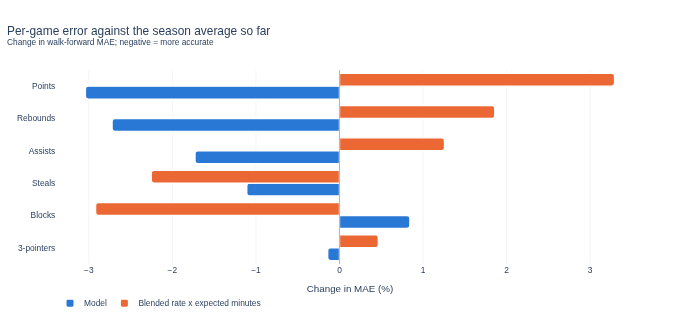

In [2]:
ev = evaluate(preds)
plot_mae(ev).show()

In [3]:
ev.pivot(index="stat", columns="method", values="mae").round(3)

method,Blended rate x expected minutes,Model,Season average so far
stat,,,
3-pointers,0.819,0.814,0.815
Assists,1.308,1.269,1.292
Blocks,0.494,0.513,0.509
Minutes,NaN,4.777,NaN
Points,4.712,4.423,4.562
Rebounds,1.969,1.881,1.933
Steals,0.682,0.690,0.698


In [4]:
by_season = evaluate(preds, by_season=True)
by_season[by_season["method"] == "Model"].pivot(index="season", columns="stat",
                                                 values="mae").round(3)

stat,3-pointers,Assists,Blocks,Minutes,Points,Rebounds,Steals
season,,,,,,,
2016,0.653,1.192,0.503,4.871,4.224,1.892,0.694
2017,0.705,1.197,0.500,4.829,4.229,1.866,0.692
2018,0.752,1.234,0.509,4.726,4.316,1.869,0.694
2019,0.802,1.275,0.522,4.775,4.467,1.920,0.688
2020,0.851,1.270,0.521,4.725,4.542,1.901,0.686
2021,0.848,1.266,0.509,4.753,4.436,1.874,0.683
2022,0.867,1.283,0.510,4.891,4.514,1.899,0.684
2023,0.859,1.271,0.512,4.818,4.523,1.884,0.680
2024,0.853,1.322,0.525,4.773,4.464,1.848,0.668


## Distributions

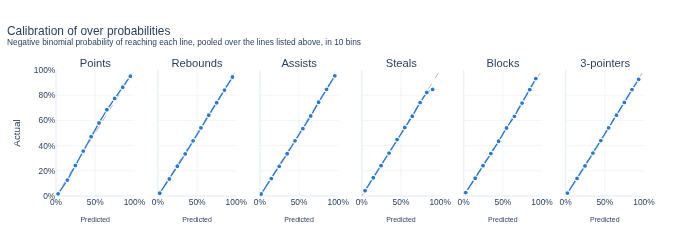

In [5]:
plot_over_calibration({s: over_calibration(preds, s) for s in STATS}).show()

In [6]:
pd.DataFrame(LINES.items(), columns=["stat", "lines"]).set_index("stat")

,lines
stat,
pts,"[10, 15, 20, 25, 30]"
trb,"[4, 6, 8, 10, 12]"
ast,"[2, 4, 6, 8, 10]"
stl,"[1, 2, 3]"
blk,"[1, 2, 3]"
fg3,"[1, 2, 3, 4, 5]"


In [7]:
interval_coverage(preds).round(3)

,stat,coverage
0,Points,0.854
1,Rebounds,0.883
2,Assists,0.915
3,Steals,0.948
4,Blocks,0.954
5,3-pointers,0.942


In [8]:
sizes.pivot_table(index=["stat", "minutes"], values="size",
                  aggfunc=["median", "min", "max"]).round(2)

median    min      max
                size   size     size
stat minutes                        
ast  0-16       2.29   2.22     2.40
     16-24      6.28   6.16     6.56
     24-30     12.71  11.84    13.23
     30-36     26.34  24.86    30.53
     36-48     49.84  43.28    55.07
blk  0-16       1.80   1.72     1.93
     16-24      4.43   4.17     5.06
     24-30      7.70   7.35     8.53
     30-36     10.06   9.16    10.81
     36-48     11.67   7.81    17.84
fg3  0-16       1.79   1.74     1.83
     16-24      4.94   4.39     5.22
     24-30      8.58   7.66     8.96
     30-36     14.77  12.71    16.12
     36-48     22.80  16.58    25.88
pts  0-16       0.93   0.91     0.94
     16-24      2.46   2.44     2.52
     24-30      4.51   4.37     4.57
     30-36      8.45   8.19     8.72
     36-48     13.10  12.48    13.57
stl  0-16       2.48   2.28     2.54
     16-24      5.96   5.62     6.97
     24-30     10.63   9.92    13.14
     30-36     24.93  22.86    36.17
     36-48    165.21  43.73  2980.94
trb  0-16       2.54   2.48     2.59
     16-24      7.46   7.26     7.50
     24-30     13.15  11.62    13.70
     30-36     23.72  22.22    24.55
     36-48     29.22  26.17    33.06

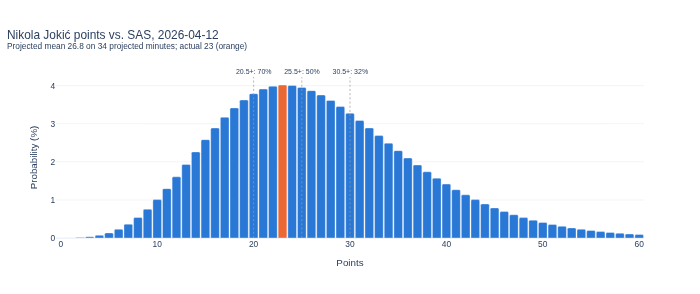

In [9]:
last_day = preds[preds["date"] == preds["date"].max()]
star = last_day.loc[last_day["pts_pred"].idxmax()]
plot_distribution(star, "pts", [20.5, 25.5, 30.5]).show()

## Game situations

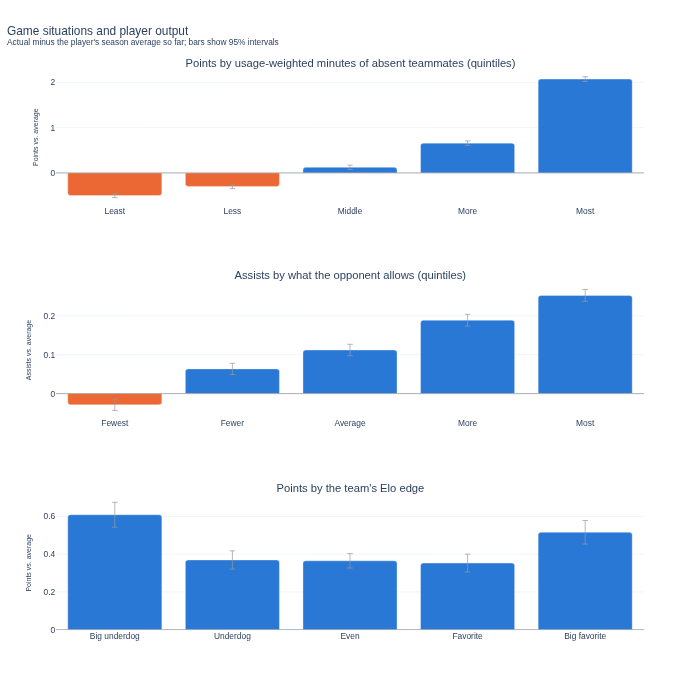

In [10]:
panels = {
    "Points by usage-weighted minutes of absent teammates (quintiles)": (
        "pts", pd.qcut(preds["missing_usg_mp"], 5,
                       labels=["Least", "Less", "Middle", "More", "Most"])),
    "Assists by what the opponent allows (quintiles)": (
        "ast", pd.qcut(preds["opp_allows_ast"], 5,
                       labels=["Fewest", "Fewer", "Average", "More", "Most"])),
    "Points by the team's Elo edge": (
        "pts", pd.cut(preds["elo_edge"], [-1000, -200, -75, 75, 200, 1000],
                      labels=["Big underdog", "Underdog", "Even", "Favorite",
                              "Big favorite"])),
}
plot_residual_by(preds, panels).show()